In [1]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit

import pandas as pd
import numpy as np
import os

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import load_iris

In [8]:
df = pd.read_csv("/home/callum/projects/ub_predictor/data/processed/20261001_154827_sites_test/features_complete_readable.csv")
top_features = [
    "acidic_fraction_in_window",
    "basic_fraction_in_window",
    "distance_to_nearest_acidic_residue_DE",
    "distance_to_nearest_basic_residue_KRH",
    "net_charge_in_window",
    "lysine_surface_exposure",
    "mean_surface_exposure_8A_neighbourhood",
    "hydrophobic_fraction_in_window",
    "residue_count_8A_neighbourhood",
    "alphafold_confidence_score_lysine",
]

met_cols = "uniprot_id,lysine_position,modified".split(",")

col_names = met_cols + top_features
df = df[col_names] 

In [9]:

print(df.shape)

# clean up data frame by removing NaNs
df = df.dropna()
print(df.shape)

(392, 13)
(381, 13)


In [18]:
# split into train and test subsets
X = df[top_features]
y = df["modified"]

'''then can use train_test_split
or group_shuffle_split, depending on if there are clusers/ groups

'''

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.35, random_state= 42)

# look at new datasets
print("training set:", X_train.shape, "test set:", X_test.shape)

training set: (247, 10) test set: (134, 10)


In [19]:
# feature scaling
# fit and transform train set then transform test set
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [ ]:
'''can add PCA step here -  i will revisit this once i understand it 
'''

In [22]:
# building the classifier
# this is where you choose the parameters
classifier = RandomForestClassifier(n_estimators=50, class_weight="balanced", random_state=42)

#fit classifier to training data
classifier.fit(X_train, y_train)

# then get predicted y values (in this case modification)
# essentially apply classifier to test data
y_pred = classifier.predict(X_test)


Accuracy: 73.88%


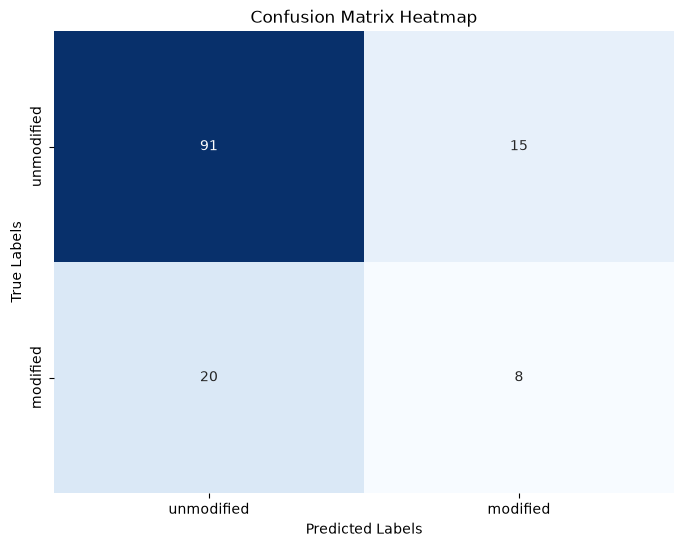

In [23]:
# Evaluation
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')

conf_matrix = confusion_matrix(y_test, y_pred)

labels = ["unmodified", "modified"]

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='g', cmap='Blues', cbar=False, 
            xticklabels=labels, yticklabels=labels)

plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()